# Fresh Eyes on CMIP - Aggregating Data Analysis Tools

Analysis of CMIP datasets in the upcoming CMIP7 phase and beyond can be greatly facilitated by collecting existing data analysis tools and code developed by scientists worldwide to analyze CMIP6 and CMIP5 data in a well-documented GitHub repository.

This project therefore aims to bring together CMIP data analysis tools developed by members of the Fresh Eyes on CMIP community in a shared GitHub repository, promoting code reuse and facilitating future CMIP data analysis.

## Introduction

This notebook illustrates how to easily access [CMIP7](https://wcrp-cmip.github.io/cmip7-guidance/docs/CMIP7/Guidance_for_users/) data and perform basic data analysis tasks.

In [1]:
import requests
import fsspec

import numpy as np
import xarray

import matplotlib.pyplot as plt

## Data search in the ESGF

CMIP7 model output is available through a distributed data archive developed and operated by the [Earth System Grid Federation (ESGF)](https://esgf.github.io/). The data are hosted across a network of nodes located at climate modelling centres and data centres around the world.

ESGF is an international collaboration of groups, agencies, and institutions dedicated to developing and operating a long-term system for managing, accessing, and analysing climate data. Its architecture is based on a network of distributed nodes. Data nodes host the available datasets, while index nodes maintain catalogues that allow users to search for data across the network.

Users can connect to any ESGF node through a web browser or a desktop client to search for and access data across the federation. However, individual nodes may occasionally become unavailable, which can temporarily prevent access to some datasets.

There are three options for accessing the data:

1. Metagrid - Metagrid provides a web interface for searching and downloading ESGF data. It is best suited for browsing datasets and downloading a small number of files. Users can search across the distributed archive as though the data were stored in a single central location. Available Metagrid portals:
   - [West index (ORNL)](https://metagrid.esgf-west.org/)
   - [West index (NERSC)](https://metagrid-nersc.west.esgf.io/)
   - [East index](https://metagrid-ceda.east.esgf.io/search)

2. APIs - For larger searches or bulk downloads, automated tools may be more suitable. Several software packages are available for interacting with the ESGF indexes and retrieving data.
   - [ESGpull](https://esgf.github.io/esgf-download/) - Version 0.10.0 supports interaction with the CMIP7 indexes but requires some configuration. Refer to the documentation for setup instructions.
   - [intake-esgf](https://github.com/esgf2-us/intake-esgf) - Version 2026.9.4 supports interaction with the CMIP7 indexes.

In [2]:
UKCM2_0_LL = [
    "https://esgf.ceda.ac.uk/data/esg_cmip7/MIP-DRS7/CMIP7/CMIP/UKNCSP/UKCM2-0-LL/historical/r1i1p1f1/glb/mon/tas/tavg-h2m-hxy-u/g110/v20260909/tas_tavg-h2m-hxy-u_mon_glb_g110_UKCM2-0-LL_historical_r1i1p1f1_185001-194912.nc",
    "https://esgf.ceda.ac.uk/data/esg_cmip7/MIP-DRS7/CMIP7/CMIP/UKNCSP/UKCM2-0-LL/historical/r1i1p1f1/glb/mon/tas/tavg-h2m-hxy-u/g110/v20260909/tas_tavg-h2m-hxy-u_mon_glb_g110_UKCM2-0-LL_historical_r1i1p1f1_195001-202112.nc",
]

For this example notebook, we will perform the downloads using simple Python code based on the `requests` module.

In [3]:
for url in UKCM2_0_LL:
    filename = url.split("/")[-1] # obtain the local filename
    with open(filename, "wb") as f:
        f.write(requests.get(url).content)

## A very simple climate analysis task

Now that we have obtained our datasets of interest, it is time to start analyzing them. For this task, we will use [xarray](https://docs.xarray.dev/en/stable/), although users are free to choose whichever data analysis package they prefer.

Rather than dealing with each file separately, we instruct xarray to construct a single dataset from the two original source files. We achieve this with the [open_mfdataset](https://docs.xarray.dev/en/stable/generated/xarray.open_mfdataset.html) function.

In [4]:
ds = xarray.open_mfdataset(
    [f.split("/")[-1] for f in UKCM2_0_LL],
    coords="minimal", compat="no_conflicts").chunk({"time": 1032})

ds["tas"]

<xarray.DataArray 'tas' (time: 2064, lat: 144, lon: 192)> Size: 228MB
dask.array<rechunk-merge, shape=(2064, 144, 192), dtype=float32, chunksize=(1032, 144, 192), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 17kB 1850-01-16T12:00:00 ... 2021-12-16T12...
  * lat      (lat) float64 1kB -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
  * lon      (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
    height   float64 8B 1.5
Attributes:
    standard_name:  air_temperature
    long_name:      Near-Surface Air Temperature
    units:          K
    original_name:  mo: (stash: m01s03i236, lbproc: 128)
    cell_methods:   area: time: mean
    history:        2026-09-03T09:33:42Z altered by CMOR: Treated scalar dime...
    cell_measures:  area: areacella

We now have our data loaded into xarray, so we can start analyzing it. As a simple example, we will compute and plot the monthly mean and the 12-month rolling mean of the surface temperature simulated by the `UKCM2_0_LL` climate model.

To account for the variation in grid cell area with latitude, we will weight the surface temperature by the cosine of latitude when computing the spatial mean. The next cell shows the results.

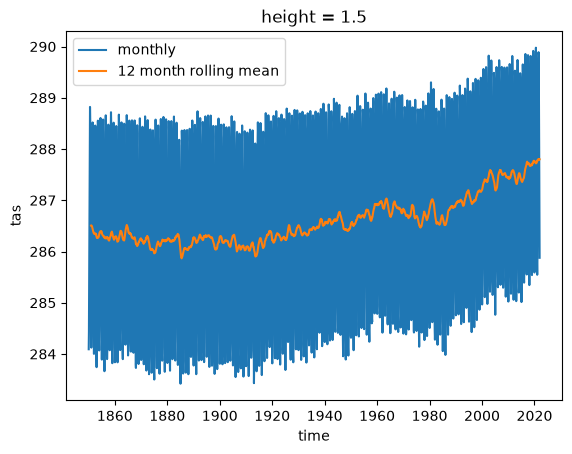

In [5]:
weights = np.cos(np.deg2rad(ds.lat))

ds["tas"].weighted(weights).mean(["lat", "lon"]).plot(label="monthly")
ds["tas"].weighted(weights).mean(["lat", "lon"]).rolling(time=12).mean().plot(label="12 month rolling mean")

plt.legend()
plt.show()